In [23]:
import pandas as pd
from sklearn.model_selection import train_test_split 
from sklearn.naive_bayes import GaussianNB

In [24]:
df=pd.read_csv('titanic.csv')
df.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C


In [25]:
inputs=df[['Pclass','Sex','Age','Fare']]
target=df['Survived']

In [27]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

inputs['Sex'] = le.fit_transform(inputs['Sex'])

C:\Users\VIVEK V\AppData\Local\Temp\ipykernel_27772\1029292321.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  inputs['Sex'] = le.fit_transform(inputs['Sex'])


In [28]:
inputs.head(2)

,Pclass,Sex,Age,Fare
0,3,1,22.0,7.2500
1,1,0,38.0,71.2833


In [31]:
inputs.columns[inputs.isna().any()]

Index([], dtype='object')

In [32]:
inputs.Age=inputs.Age.fillna(inputs.Age.mean())

C:\Users\VIVEK V\AppData\Local\Temp\ipykernel_27772\925655445.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  inputs.Age=inputs.Age.fillna(inputs.Age.mean())


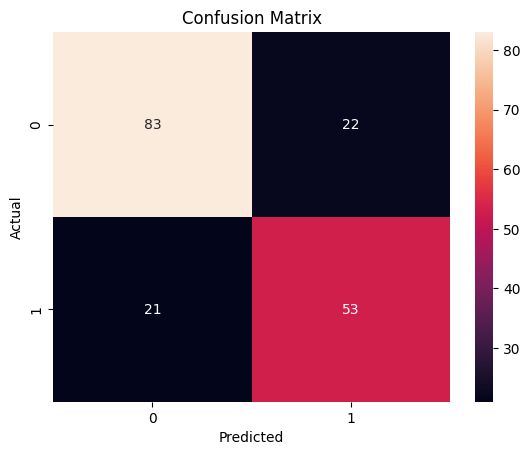

              precision    recall  f1-score   support

           0       0.80      0.79      0.79       105
           1       0.71      0.72      0.71        74

    accuracy                           0.76       179
   macro avg       0.75      0.75      0.75       179
weighted avg       0.76      0.76      0.76       179

Accuracy: 0.7597765363128491


In [34]:
from sklearn.metrics import confusion_matrix,classification_report
import seaborn as sns
import matplotlib.pyplot as plt

x_train, x_test, y_train, y_test = train_test_split(
    inputs, target, test_size=0.2, random_state=42
)

model = GaussianNB()
model.fit(x_train, y_train)

# Predict
y_pred = model.predict(x_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Plot heatmap
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=model.classes_,
            yticklabels=model.classes_)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()
print(classification_report(y_test,y_pred))
print("Accuracy:", model.score(x_test, y_test))